# Does one algorithm consistently beat the others? Model comparison on four datasets

This notebook reruns the full protocol behind `README.md` from the CSV files in `data/`:

1. Load the four datasets (blood-transfusion, banknote, credit-g, spambase)
2. Define five model families with small hyper-parameter grids
3. **Nested, repeated cross-validation** (5 × repeated stratified 5-fold outside, 3-fold grid search inside)
4. **Statistical tests**: naive vs corrected (Nadeau & Bengio) paired t-test, Friedman + Nemenyi across datasets
5. **Held-out study**: bootstrap CI on AUC, calibration, split-conformal prediction sets

Set `QUICK_RUN = True` in the configuration cell for a fast reduced run (3 folds × 1 repeat); the full run takes tens of minutes on CPU.

## 0. Imports and configuration

In [1]:
import itertools
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")  # silence convergence / future warnings for readable output

# ---- Configuration -------------------------------------------------------
QUICK_RUN = False          # True = 3 folds x 1 repeat (fast sanity check); False = full protocol (5 x 5)
SEED = 0                   # one seed drives every split and every stochastic model
DATA_DIR = Path("data")    # folder containing the four CSV files
OUTER_FOLDS, OUTER_REPEATS = (3, 1) if QUICK_RUN else (5, 5)
INNER_FOLDS = 3            # folds of the inner grid search used for tuning
ALPHA = 0.05               # significance level for all tests
CONFORMAL_ALPHA = 0.10     # conformal sets target 1 - 0.10 = 90 % coverage

# ---- Colours (colour-blind-safe Okabe-Ito palette), reused by every figure ----
MODEL_COLORS = {"logreg": "#0072B2", "knn": "#E69F00", "mlp": "#CC79A7",
                "random-forest": "#009E73", "hist-gbm": "#D55E00"}
CLASS_COLORS = {0: "#56B4E9", 1: "#D55E00"}      # negative / positive class
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12})

## 1. Data

Each dataset is one CSV file. For every dataset we record the name of the target column and which
value is the **positive class** (the class the model scores). Categorical columns are one-hot encoded
and missing values are median-imputed.

In [2]:
# name -> (target column, positive class, OpenML id)
SUITE = {
    "blood-transfusion": ("Class", "2", 1464),    # positive = donor gives blood in March 2007
    "banknote":          ("Class", "2", 1462),    # positive = class 2 of the banknote labels
    "credit-g":          ("class", "bad", 31),    # positive = bad credit risk
    "spambase":          ("class", "1", 44),      # positive = spam
}


def load_dataset(name):
    """Read data/<name>.csv and return (X, y, feature_names) as numpy arrays."""
    target, positive, _ = SUITE[name]
    df = pd.read_csv(DATA_DIR / f"{name}.csv", dtype={target: str})
    y = (df.pop(target).astype(str) == positive).astype(int).to_numpy()        # binary target 0/1
    categorical = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    X = pd.get_dummies(df, columns=categorical, drop_first=False, dtype=float)  # one-hot encoding
    X = X.fillna(X.median(numeric_only=True))                                   # median imputation
    return X.to_numpy(dtype=float), y, list(X.columns)


DATASETS = {name: load_dataset(name) for name in SUITE}

# Overview table (rows, features after one-hot, positive rate)
pd.DataFrame(
    [{"dataset": n, "openml_id": SUITE[n][2], "rows": len(y), "features": X.shape[1], "positive_rate": round(y.mean(), 3)}
     for n, (X, y, _) in DATASETS.items()]
)

,dataset,openml_id,rows,features,positive_rate
0,blood-transfusion,1464,748,4,0.238
1,banknote,1462,1372,4,0.445
2,credit-g,31,1000,61,0.300
3,spambase,44,4601,57,0.394


### 1.1 Exploratory figures

Left: class balance of each dataset (how rare the positive class is). Below: histograms of the four features most
correlated with the target, split by class (blue = negative, orange = positive). Features are clipped at their
99th percentile for display only.

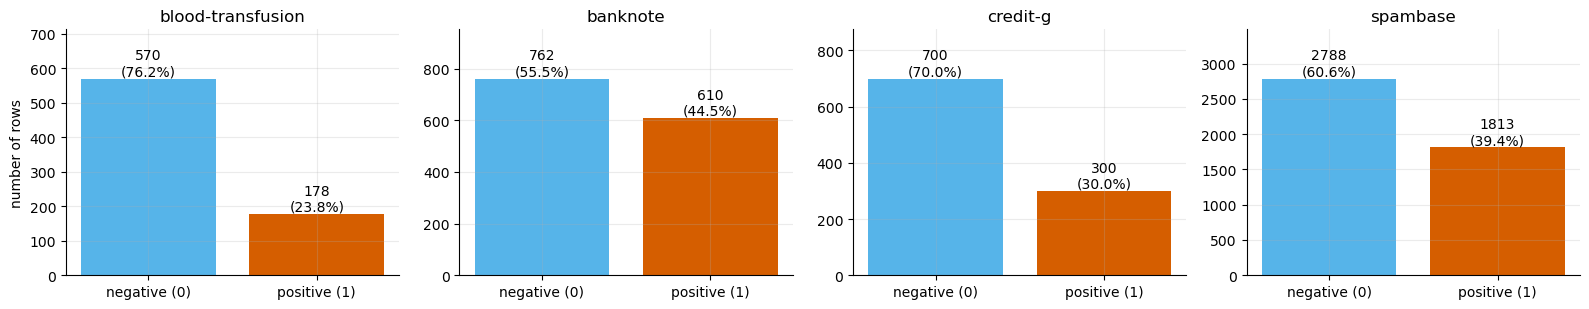

In [3]:
# Class balance: number of rows per class for each dataset
fig, axes = plt.subplots(1, len(DATASETS), figsize=(4 * len(DATASETS), 3.2))
for ax, (name, (X, y, _)) in zip(axes, DATASETS.items()):
    counts = np.bincount(y, minlength=2)
    bars = ax.bar(["negative (0)", "positive (1)"], counts, color=[CLASS_COLORS[0], CLASS_COLORS[1]])
    ax.bar_label(bars, labels=[f"{c}\n({c / len(y):.1%})" for c in counts])
    ax.set_title(name); ax.set_ylim(0, counts.max() * 1.25)
axes[0].set_ylabel("number of rows")
plt.tight_layout(); plt.show()

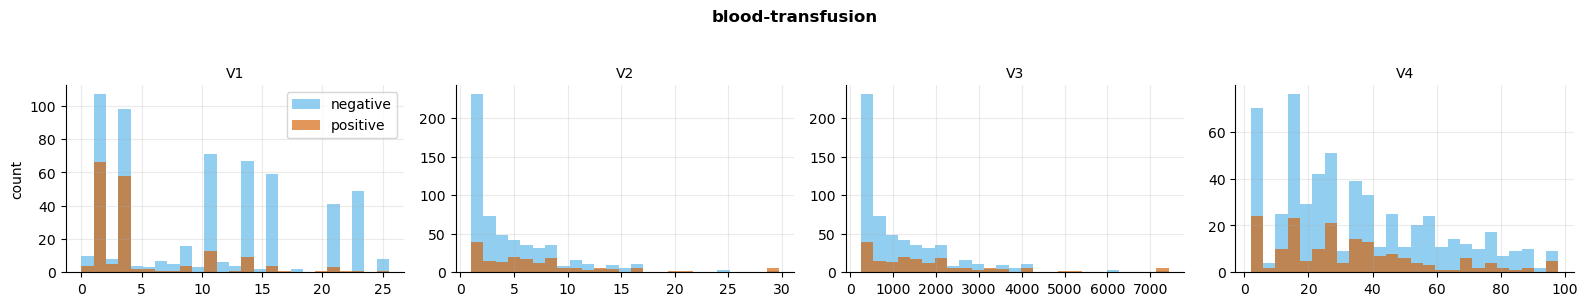

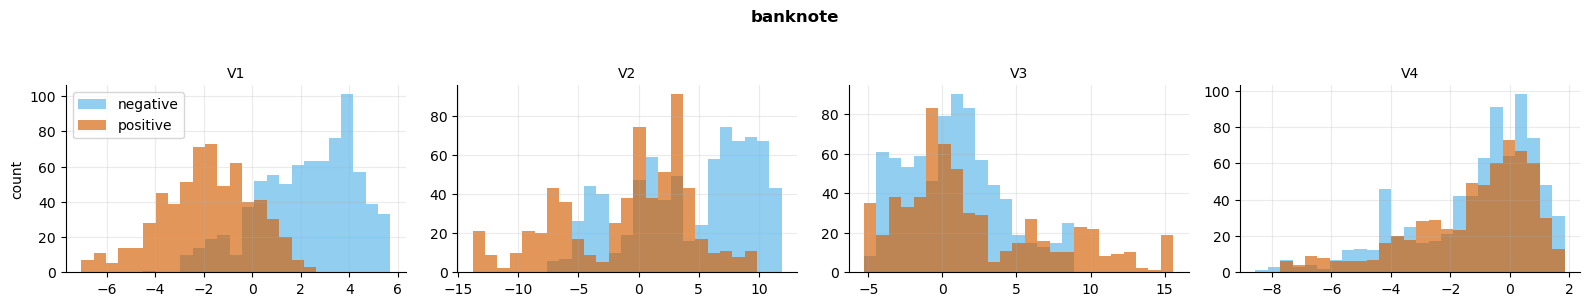

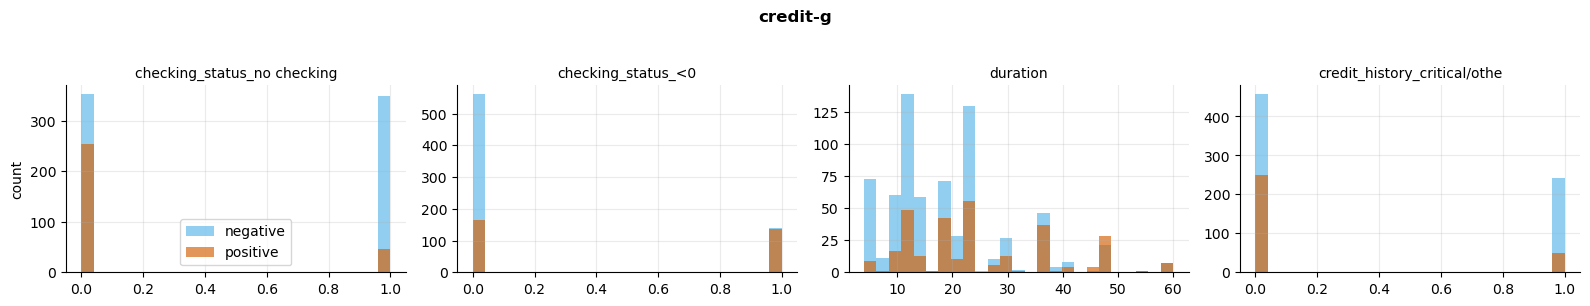

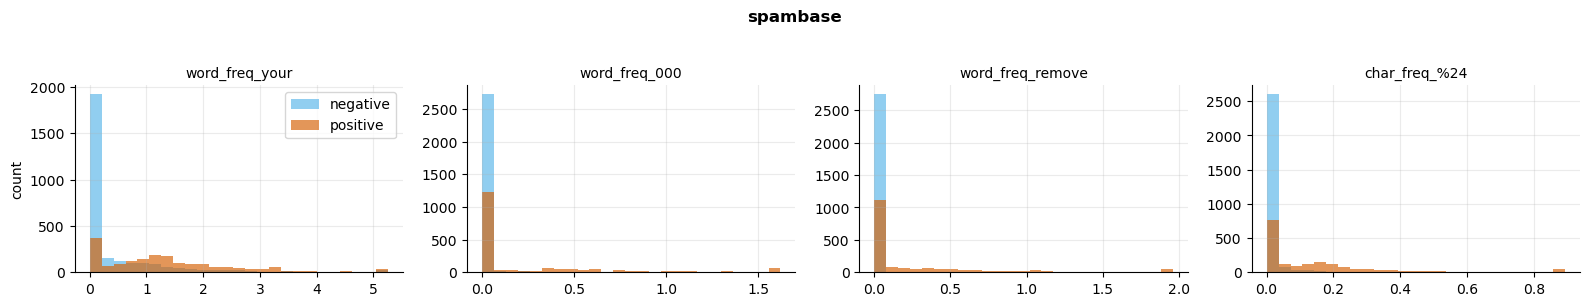

In [4]:
# Histograms of the 4 features most correlated with the target, one row of plots per dataset
for name, (X, y, feats) in DATASETS.items():
    corr = np.nan_to_num([abs(np.corrcoef(X[:, j], y)[0, 1]) for j in range(X.shape[1])])
    top = np.argsort(corr)[::-1][:4]
    fig, axes = plt.subplots(1, 4, figsize=(16, 2.9))
    for ax, j in zip(axes, top):
        hi = np.percentile(X[:, j], 99)
        bins = np.histogram_bin_edges(np.clip(X[:, j], None, hi), bins=25)
        for c, label in ((0, "negative"), (1, "positive")):
            ax.hist(np.clip(X[y == c, j], None, hi), bins=bins, alpha=0.65, color=CLASS_COLORS[c], label=label)
        ax.set_title(feats[j][:28], fontsize=10)
    axes[0].set_ylabel("count"); axes[0].legend()
    fig.suptitle(name, y=1.04, fontweight="bold"); plt.tight_layout(); plt.show()

## 2. Statistical helpers

* `corrected_ttest`: Nadeau & Bengio (2003) corrected resampled t-test. Cross-validation folds share
  training data, so the plain paired t-test underestimates the variance. The correction adds the
  test/train size ratio to the variance term.
* `naive_ttest`: the plain paired t-test, kept only to show how much it overstates significance.
* `average_ranks` / `friedman_nemenyi`: Demšar (2006) procedure to compare several models over several datasets.
* `bootstrap_ci`: percentile bootstrap confidence interval for any metric.
* `expected_calibration_error`: binned ECE for binary probabilities.

In [5]:
# Studentised range statistic / sqrt(2) at alpha = 0.05 for k = 2..10 models (Demsar 2006, Table 5)
NEMENYI_Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}


def corrected_ttest(a, b, test_train_ratio):
    """Two-sided p-value of the Nadeau-Bengio corrected paired t-test on CV scores a and b."""
    d = np.asarray(a, float) - np.asarray(b, float)
    n, var = len(d), d.var(ddof=1)
    if var == 0:
        return (0.0, 1.0) if d.mean() == 0 else (float(np.sign(d.mean()) * np.inf), 0.0)
    t = d.mean() / np.sqrt((1 / n + test_train_ratio) * var)   # the correction: 1/n + n_test/n_train
    return float(t), float(2 * stats.t.sf(abs(t), df=n - 1))


def naive_ttest(a, b):
    """Plain paired t-test (ignores the overlap between training sets)."""
    d = np.asarray(a, float) - np.asarray(b, float)
    if d.var(ddof=1) == 0:
        return (0.0, 1.0) if d.mean() == 0 else (float(np.sign(d.mean()) * np.inf), 0.0)
    res = stats.ttest_1samp(d, 0.0)
    return float(res.statistic), float(res.pvalue)


def average_ranks(scores, higher_is_better=True):
    """scores has shape (datasets, models). Rank 1 = best; ties receive the mean rank."""
    s = -scores if higher_is_better else scores
    return np.vstack([stats.rankdata(row) for row in s]).mean(axis=0)


def friedman_nemenyi(scores, higher_is_better=True):
    """Friedman test on ranks + Nemenyi critical difference (in rank units)."""
    n_data, k = scores.shape
    ranks = average_ranks(scores, higher_is_better)
    s = -scores if higher_is_better else scores
    chi2, p = stats.friedmanchisquare(*[s[:, j] for j in range(k)])
    cd = NEMENYI_Q05[k] * np.sqrt(k * (k + 1) / (6 * n_data))
    return {"avg_ranks": ranks, "friedman_chi2": float(chi2), "friedman_p": float(p), "cd": float(cd)}


def bootstrap_ci(y_true, y_score, metric, n_boot=1000, alpha=0.05, seed=0):
    """Return (point estimate, lower, upper) of a percentile bootstrap CI."""
    rng = np.random.default_rng(seed)
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    point, n, vals = metric(y_true, y_score), len(y_true), []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:       # skip resamples with a single class
            continue
        vals.append(metric(y_true[idx], y_score[idx]))
    lo, hi = np.quantile(vals, [alpha / 2, 1 - alpha / 2])
    return float(point), float(lo), float(hi)


def expected_calibration_error(y_true, proba, bins=10):
    """ECE: weighted mean gap between predicted probability and observed frequency per bin."""
    y_true, proba = np.asarray(y_true, float), np.asarray(proba, float)
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(proba, edges[1:-1]), 0, bins - 1)
    ece = 0.0
    for b in range(bins):
        mask = idx == b
        if mask.any():
            ece += mask.mean() * abs(y_true[mask].mean() - proba[mask].mean())
    return float(ece)

## 3. Model zoo

Five model families, each with a small explicit hyper-parameter grid that is tuned by the inner
cross-validation (scoring = ROC AUC). Logistic regression, k-NN and the MLP are preceded by feature
standardisation; tree models do not need it.

In [6]:
def model_zoo(seed=SEED):
    """Return {name: (estimator, grid)}."""
    return {
        "logreg": (
            make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
            {"logisticregression__C": [0.1, 1.0, 10.0]},
        ),
        "knn": (
            make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": [15, 31]},
        ),
        "mlp": (
            make_pipeline(StandardScaler(),
                          MLPClassifier(hidden_layer_sizes=(64,), early_stopping=True, max_iter=500, random_state=seed)),
            {"mlpclassifier__alpha": [1e-4, 1e-2]},
        ),
        "random-forest": (
            RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=-1),
            {"min_samples_leaf": [1, 5]},
        ),
        "hist-gbm": (
            HistGradientBoostingClassifier(random_state=seed),
            {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31]},
        ),
    }


MODELS = list(model_zoo())
MODELS

['logreg', 'knn', 'mlp', 'random-forest', 'hist-gbm']

## 4. Nested, repeated cross-validation

* **Outer loop**: repeated stratified k-fold. Every model sees exactly the same outer splits, so the scores are *paired*.
* **Inner loop**: a 3-fold grid search on the outer training part only, so tuning never sees the outer test fold.
* For each (model, outer fold) we record AUC, log loss, Brier score, ECE and fit time.

In [7]:
def nested_cv(name, X, y, zoo, folds=OUTER_FOLDS, repeats=OUTER_REPEATS, inner_folds=INNER_FOLDS, seed=SEED):
    """One row per (model, outer fold) with the test metrics of the tuned model."""
    outer = RepeatedStratifiedKFold(n_splits=folds, n_repeats=repeats, random_state=seed)
    splits = list(outer.split(X, y))                       # same splits for every model -> paired scores
    rows = []
    for model_name, (estimator, grid) in zoo.items():
        for fold, (tr, te) in enumerate(splits):
            inner = StratifiedKFold(inner_folds, shuffle=True, random_state=seed + fold)
            search = GridSearchCV(clone(estimator), grid, scoring="roc_auc", cv=inner)
            t0 = time.perf_counter()
            search.fit(X[tr], y[tr])                       # tune on the outer training part only
            fit_s = time.perf_counter() - t0
            proba = np.clip(search.predict_proba(X[te])[:, 1], 1e-6, 1 - 1e-6)
            rows.append({
                "dataset": name, "model": model_name, "fold": fold,
                "auc": roc_auc_score(y[te], proba),
                "log_loss": log_loss(y[te], proba, labels=[0, 1]),
                "brier": brier_score_loss(y[te], proba),
                "ece": expected_calibration_error(y[te], proba),
                "fit_seconds": fit_s,
                "best_params": str(search.best_params_),
            })
    return pd.DataFrame(rows)

### 4.1 Run the benchmark (slowest cell)

In [8]:
zoo = model_zoo()
all_folds = []
for name, (X, y, _) in DATASETS.items():
    f = nested_cv(name, X, y, zoo)
    all_folds.append(f)
    best = f.groupby("model")["auc"].mean().sort_values(ascending=False)
    print(f"{name:18s} best = {best.index[0]:14s} AUC = {best.iloc[0]:.4f}", flush=True)

folds_df = pd.concat(all_folds, ignore_index=True)   # one row per (dataset, model, outer fold)
folds_df.head()

blood-transfusion  best = logreg         AUC = 0.7523
banknote           best = random-forest  AUC = 0.9999
credit-g           best = random-forest  AUC = 0.7939
spambase           best = hist-gbm       AUC = 0.9888


,dataset,model,fold,auc,log_loss,brier,ece,fit_seconds,best_params
0,blood-transfusion,logreg,0,0.742568,0.479180,0.153887,0.058502,0.098623,{'logisticregression__C': 0.1}
1,blood-transfusion,logreg,1,0.792154,0.453594,0.146718,0.061582,0.106465,{'logisticregression__C': 0.1}
2,blood-transfusion,logreg,2,0.705166,0.499499,0.164467,0.051885,0.088787,{'logisticregression__C': 0.1}
3,blood-transfusion,logreg,3,0.785338,0.468240,0.154846,0.080189,0.097363,{'logisticregression__C': 0.1}
4,blood-transfusion,logreg,4,0.738722,0.488788,0.156291,0.060281,0.273167,{'logisticregression__C': 0.1}


credit-g           best = random-forest  AUC = 0.7939


spambase           best = hist-gbm       AUC = 0.9891


,dataset,model,fold,auc,log_loss,brier,ece,fit_seconds,best_params
0,blood-transfusion,logreg,0,0.742568,0.479180,0.153887,0.058502,0.058653,{'logisticregression__C': 0.1}
1,blood-transfusion,logreg,1,0.792154,0.453594,0.146718,0.061582,0.044965,{'logisticregression__C': 0.1}
2,blood-transfusion,logreg,2,0.705166,0.499499,0.164467,0.051885,0.044127,{'logisticregression__C': 0.1}
3,blood-transfusion,logreg,3,0.785338,0.468240,0.154846,0.080189,0.044913,{'logisticregression__C': 0.1}
4,blood-transfusion,logreg,4,0.738722,0.488788,0.156291,0.060281,0.046013,{'logisticregression__C': 0.1}


## 5. Results

### 5.1 ROC AUC per dataset and model (mean ± sd over the outer folds)

In [9]:
mean_auc = folds_df.pivot_table(index="dataset", columns="model", values="auc", aggfunc="mean")[MODELS].loc[list(SUITE)]
sd_auc = folds_df.pivot_table(index="dataset", columns="model", values="auc", aggfunc="std")[MODELS].loc[list(SUITE)]

auc_table = mean_auc.copy().astype(object)
for d in auc_table.index:
    for m in MODELS:
        auc_table.loc[d, m] = f"{mean_auc.loc[d, m]:.3f} ± {sd_auc.loc[d, m]:.3f}"
auc_table

model,logreg,knn,mlp,random-forest,hist-gbm
dataset,,,,,
blood-transfusion,0.752 ± 0.026,0.739 ± 0.032,0.728 ± 0.049,0.724 ± 0.032,0.713 ± 0.035
banknote,1.000 ± 0.000,0.999 ± 0.001,0.994 ± 0.002,1.000 ± 0.000,1.000 ± 0.000
credit-g,0.785 ± 0.027,0.757 ± 0.033,0.756 ± 0.042,0.794 ± 0.030,0.779 ± 0.026
spambase,0.971 ± 0.005,0.960 ± 0.005,0.974 ± 0.007,0.987 ± 0.004,0.989 ± 0.003


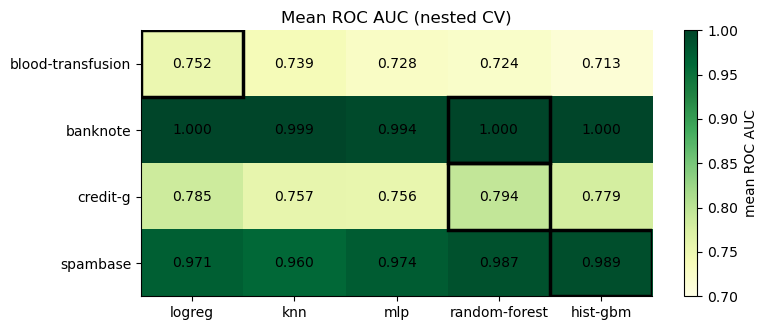

In [10]:
# Heatmap of the mean AUC (darker green = better); the best model of each dataset has a black frame
fig, ax = plt.subplots(figsize=(8, 3.4))
im = ax.imshow(mean_auc.to_numpy(), cmap="YlGn", vmin=0.7, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS)
ax.set_yticks(range(len(SUITE))); ax.set_yticklabels(list(SUITE)); ax.grid(False)
for i, d in enumerate(mean_auc.index):
    for j, m in enumerate(MODELS):
        ax.text(j, i, f"{mean_auc.loc[d, m]:.3f}", ha="center", va="center", fontsize=10)
    jb = int(np.argmax(mean_auc.loc[d].to_numpy()))
    ax.add_patch(plt.Rectangle((jb - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="black", lw=2.5))
fig.colorbar(im, ax=ax, label="mean ROC AUC"); ax.set_title("Mean ROC AUC (nested CV)")
plt.tight_layout(); plt.show()

### 5.2 Other metrics (lower is better): log loss, Brier score, ECE

In [11]:
other = folds_df.pivot_table(index="dataset", columns="model", values=["log_loss", "brier", "ece"], aggfunc="mean")
other.round(4)

brier                                            ece  \
model             hist-gbm     knn  logreg     mlp random-forest hist-gbm   
dataset                                                                     
banknote            0.0038  0.0061  0.0080  0.1476        0.0062   0.0052   
blood-transfusion   0.1651  0.1550  0.1548  0.1840        0.1582   0.0925   
credit-g            0.1687  0.1778  0.1666  0.1757        0.1652   0.0773   
spambase            0.0349  0.0749  0.0599  0.0556        0.0394   0.0181   

                                                        log_loss          \
model                 knn  logreg     mlp random-forest hist-gbm     knn   
dataset                                                                    
banknote           0.0161  0.0181  0.3210        0.0216   0.0190  0.0307   
blood-transfusion  0.0754  0.0581  0.1487        0.0758   0.5250  0.5226   
credit-g           0.0666  0.0705  0.0644        0.0691   0.5130  0.5350   
spambase           0.0355  0.0331  0.0331        0.0460   0.1283  0.2882   

                                                 
model              logreg     mlp random-forest  
dataset                                          
banknote           0.0288  0.4736        0.0298  
blood-transfusion  0.4768  0.5520        0.5007  
credit-g           0.5056  0.5273        0.4992  
spambase           0.2313  0.2028        0.1527

### 5.3 Naive vs corrected paired t-test

For every dataset and every pair of models we compare the 25 paired fold AUCs. For k-fold CV the
test/train size ratio used by the correction is 1 / (k - 1).

In [12]:
def significance(folds, ratio, alpha=ALPHA):
    """All model pairs on every dataset: naive vs corrected paired t-test on the fold AUCs."""
    rows = []
    for ds_name, g in folds.groupby("dataset"):
        piv = g.pivot(index="fold", columns="model", values="auc")
        for a, b in itertools.combinations(MODELS, 2):
            _, p_naive = naive_ttest(piv[a], piv[b])
            _, p_corr = corrected_ttest(piv[a], piv[b], ratio)
            rows.append({"dataset": ds_name, "a": a, "b": b, "mean_diff": float((piv[a] - piv[b]).mean()),
                         "p_naive": p_naive, "p_corrected": p_corr,
                         "sig_naive": p_naive < alpha, "sig_corrected": p_corr < alpha})
    return pd.DataFrame(rows)


pairs = significance(folds_df, ratio=1 / (OUTER_FOLDS - 1))
print(f"Out of {len(pairs)} model pairs x datasets: naive test significant = {int(pairs.sig_naive.sum())}, "
      f"corrected test significant = {int(pairs.sig_corrected.sum())}")
pairs.groupby("dataset")[["sig_naive", "sig_corrected"]].sum().loc[list(SUITE)]

Out of 40 model pairs x datasets: naive test significant = 30, corrected test significant = 14


,sig_naive,sig_corrected
dataset,,
blood-transfusion,6,1
banknote,6,4
credit-g,8,1
spambase,10,8


### 5.4 Which models are statistically tied with the best on each dataset?

In [13]:
ties = []
for d in SUITE:
    best = mean_auc.loc[d].idxmax()
    g = pairs[pairs.dataset == d]
    tied = [m for m in MODELS if m != best and not g[((g.a == best) & (g.b == m)) | ((g.a == m) & (g.b == best))].sig_corrected.iloc[0]]
    ties.append({"dataset": d, "best": best, "not significantly worse": ", ".join(tied) or "none"})
pd.DataFrame(ties)

,dataset,best,not significantly worse
0,blood-transfusion,logreg,"knn, mlp, random-forest"
1,banknote,random-forest,"logreg, knn, hist-gbm"
2,credit-g,random-forest,"logreg, mlp, hist-gbm"
3,spambase,hist-gbm,random-forest


### 5.5 Ranking across datasets (Friedman test + Nemenyi critical difference)

Two models differ significantly across datasets only if their average ranks differ by more than the critical difference (CD).

In [14]:
fn = friedman_nemenyi(mean_auc.to_numpy())
ranks = pd.DataFrame({"model": MODELS, "avg_rank": fn["avg_ranks"]}).sort_values("avg_rank")
print(f"Friedman chi2 = {fn['friedman_chi2']:.2f}, p = {fn['friedman_p']:.3f}; Nemenyi CD (alpha 0.05) = {fn['cd']:.2f} ranks")
ranks

Friedman chi2 = 4.60, p = 0.331; Nemenyi CD (alpha 0.05) = 3.05 ranks


,model,avg_rank
3,random-forest,2.00
0,logreg,2.50
4,hist-gbm,2.75
1,knn,3.75
2,mlp,4.00


### 5.6 Figures: distribution of fold AUCs and critical-difference view

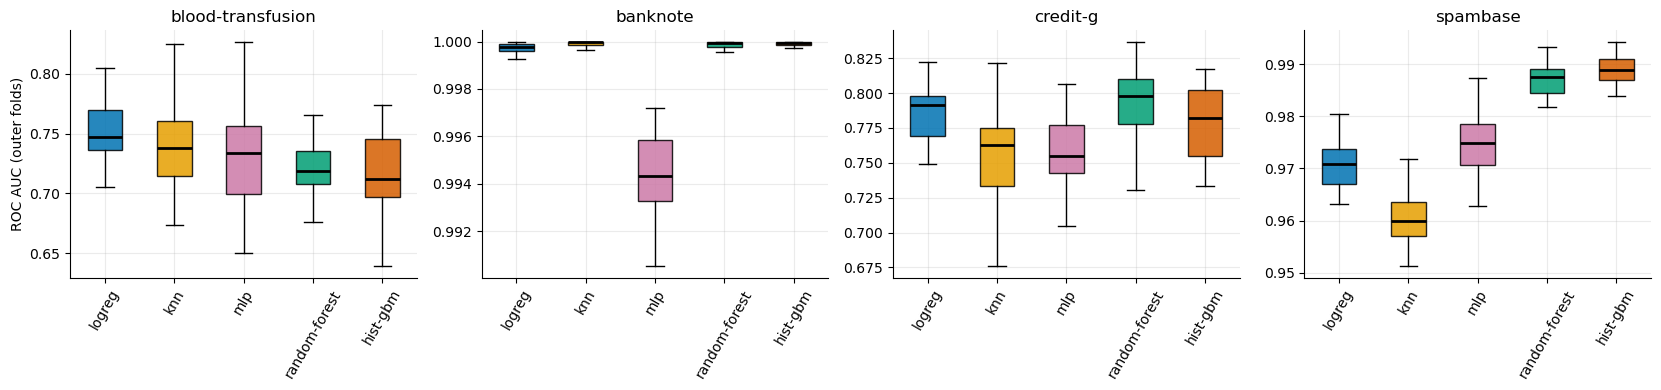

In [23]:
# Box plots: spread of the outer-fold AUCs of every model, one panel per dataset
fig, axes = plt.subplots(1, len(SUITE), figsize=(4.2 * len(SUITE), 4))
for ax, d in zip(axes, SUITE):
    data = [folds_df[(folds_df.dataset == d) & (folds_df.model == m)].auc.to_numpy() for m in MODELS]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, medianprops={"color": "black", "lw": 2})
    for patch, m in zip(bp["boxes"], MODELS):
        patch.set_facecolor(MODEL_COLORS[m]); patch.set_alpha(0.85)
    ax.set_xticks(range(1, len(MODELS) + 1)); ax.set_xticklabels(MODELS, rotation=60)
    ax.set_title(d)
axes[0].set_ylabel("ROC AUC (outer folds)")
plt.tight_layout(); plt.show()

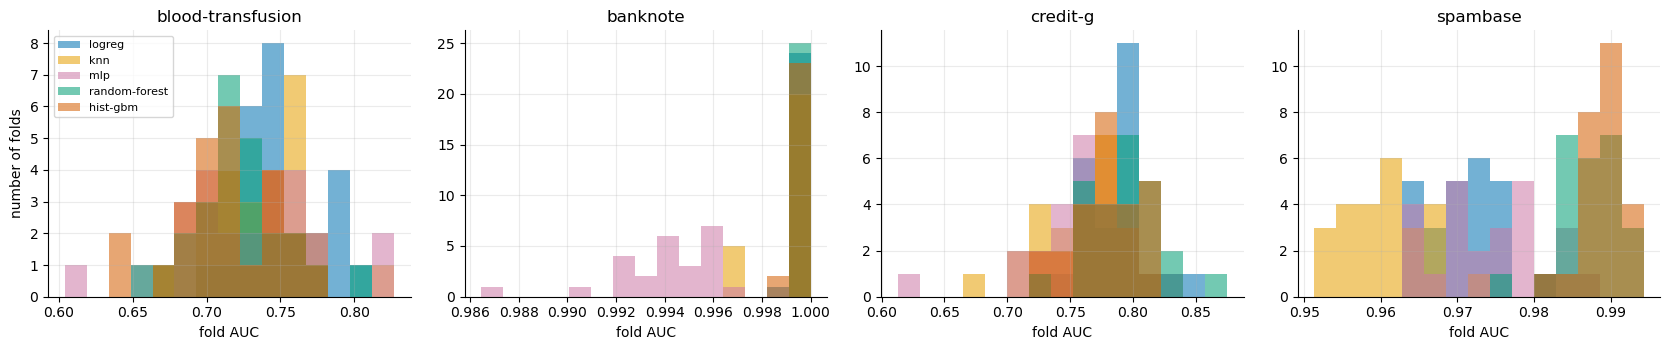

In [24]:
# Histograms: distribution of the fold AUCs (one colour per model), one panel per dataset
fig, axes = plt.subplots(1, len(SUITE), figsize=(4.2 * len(SUITE), 3.6))
for ax, d in zip(axes, SUITE):
    g = folds_df[folds_df.dataset == d]
    bins = np.histogram_bin_edges(g.auc, bins=15)
    for m in MODELS:
        ax.hist(g[g.model == m].auc, bins=bins, alpha=0.55, color=MODEL_COLORS[m], label=m)
    ax.set_title(d); ax.set_xlabel("fold AUC")
axes[0].set_ylabel("number of folds"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

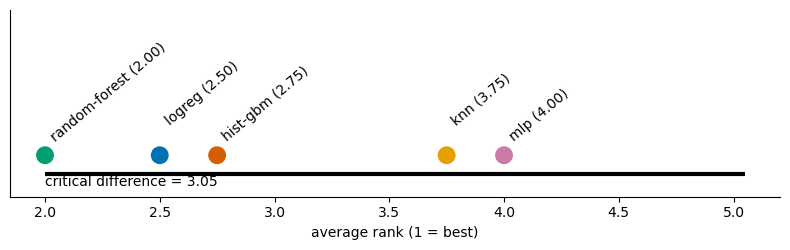

In [25]:
# Average ranks with the Nemenyi critical difference: models whose ranks differ by less than CD are not significantly different
fig, ax = plt.subplots(figsize=(8, 2.6))
r = ranks.sort_values("avg_rank")
ax.scatter(r.avg_rank, np.zeros(len(r)), s=140, c=[MODEL_COLORS[m] for m in r.model], zorder=3)
for i, (x, m) in enumerate(zip(r.avg_rank, r.model)):
    ax.annotate(f"{m} ({x:.2f})", (x, 0), rotation=40, xytext=(2, 10 + 12 * (i % 2)), textcoords="offset points", ha="left")
ax.hlines(-0.18, r.avg_rank.min(), r.avg_rank.min() + fn["cd"], color="black", lw=3)
ax.annotate(f"critical difference = {fn['cd']:.2f}", (r.avg_rank.min(), -0.3))
ax.set_yticks([]); ax.set_xlabel("average rank (1 = best)"); ax.set_ylim(-0.4, 1.4); ax.grid(False)
plt.tight_layout(); plt.show()

## 6. Held-out study (60 / 20 / 20 split)

For the models of interest we split each dataset into train (60 %), calibration (20 %) and test (20 %), then:

1. **Fit** the model on the train part (with inner-CV tuning) and score the test part. The AUC gets a bootstrap 95 % CI.
2. **Calibrate**: ECE before and after sigmoid (Platt) and isotonic recalibration fitted on the calibration part.
3. **Conformal prediction**: split-conformal sets with the score 1 - p(true class). The set contains every
   class whose score is below the (1 - alpha) quantile of the calibration scores, which guarantees about 90 % coverage.

In [26]:
def conformal_sets(cal_proba, cal_y, test_proba, alpha):
    """Split-conformal prediction sets. Returns a boolean matrix (n_test, 2): column c is True if class c is in the set."""
    p_true = np.where(cal_y == 1, cal_proba, 1 - cal_proba)
    scores = 1 - p_true                                           # non-conformity score
    n = len(scores)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)          # finite-sample corrected quantile level
    qhat = np.quantile(scores, level, method="higher")
    probs = np.column_stack([1 - test_proba, test_proba])
    return (1 - probs) <= qhat


def holdout_study(name, X, y, model_name, alpha=CONFORMAL_ALPHA, seed=SEED):
    """Train / calibration / test study for one model on one dataset."""
    estimator, grid = model_zoo(seed)[model_name]
    X_tr, X_rest, y_tr, y_rest = train_test_split(X, y, test_size=0.4, stratify=y, random_state=seed)
    X_cal, X_te, y_cal, y_te = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=seed)

    search = GridSearchCV(clone(estimator), grid, scoring="roc_auc", cv=3)
    search.fit(X_tr, y_tr)
    model = search.best_estimator_
    raw_te = model.predict_proba(X_te)[:, 1]

    out = {"dataset": name, "model": model_name, "n_test": len(y_te)}
    auc, lo, hi = bootstrap_ci(y_te, raw_te, roc_auc_score, n_boot=1000, seed=seed)    # AUC with 95 % CI
    out.update({"test_auc": auc, "auc_ci_low": lo, "auc_ci_high": hi})

    out["ece_raw"] = expected_calibration_error(y_te, raw_te)                          # calibration before / after
    for method in ("sigmoid", "isotonic"):
        try:
            from sklearn.frozen import FrozenEstimator                                 # scikit-learn >= 1.6
            cal = CalibratedClassifierCV(FrozenEstimator(model), method=method)
        except ImportError:                                                            # older scikit-learn
            cal = CalibratedClassifierCV(model, method=method, cv="prefit")
        cal.fit(X_cal, y_cal)
        out[f"ece_{method}"] = expected_calibration_error(y_te, cal.predict_proba(X_te)[:, 1])

    sets = conformal_sets(model.predict_proba(X_cal)[:, 1], y_cal, raw_te, alpha)      # conformal sets
    covered = sets[np.arange(len(y_te)), y_te]
    out.update({"conformal_target": 1 - alpha,
                "conformal_coverage": float(covered.mean()),
                "conformal_mean_set_size": float(sets.sum(axis=1).mean()),
                "conformal_singleton_rate": float((sets.sum(axis=1) == 1).mean())})
    return out

In [27]:
# Same models as in the README: the best model by average rank and the logistic-regression baseline.
top_model = ranks.iloc[0]["model"]
HOLDOUT_MODELS = sorted({top_model, "logreg"})
holdout_df = pd.DataFrame([holdout_study(n, X, y, m) for n, (X, y, _) in DATASETS.items() for m in HOLDOUT_MODELS])
print(f"Mean conformal coverage: {holdout_df.conformal_coverage.mean():.3f} (target {1 - CONFORMAL_ALPHA:.2f})")
holdout_df.round(3)

Mean conformal coverage: 0.911 (target 0.90)


,dataset,model,n_test,test_auc,auc_ci_low,auc_ci_high,ece_raw,ece_sigmoid,ece_isotonic,conformal_target,conformal_coverage,conformal_mean_set_size,conformal_singleton_rate
0,blood-transfusion,logreg,150,0.712,0.616,0.803,0.028,0.050,0.088,0.9,0.887,1.300,0.700
1,blood-transfusion,random-forest,150,0.688,0.583,0.793,0.078,0.054,0.068,0.9,0.887,1.340,0.660
2,banknote,logreg,275,1.000,1.000,1.000,0.015,0.021,0.007,0.9,0.938,0.938,0.938
3,banknote,random-forest,275,1.000,1.000,1.000,0.021,0.013,0.005,0.9,0.909,0.909,0.909
4,credit-g,logreg,200,0.800,0.731,0.856,0.057,0.065,0.030,0.9,0.910,1.380,0.620
5,credit-g,random-forest,200,0.831,0.771,0.885,0.057,0.050,0.036,0.9,0.905,1.360,0.640
6,spambase,logreg,921,0.977,0.967,0.986,0.043,0.065,0.025,0.9,0.938,0.992,0.992
7,spambase,random-forest,921,0.990,0.982,0.997,0.065,0.020,0.013,0.9,0.916,0.929,0.929


### 6.1 ROC curves on the held-out test set

All five models are tuned on the 60 % training part and scored on the same 20 % test part (same split as above,
so logistic regression and random forest reproduce the AUCs of the table). The dashed diagonal is a random classifier.

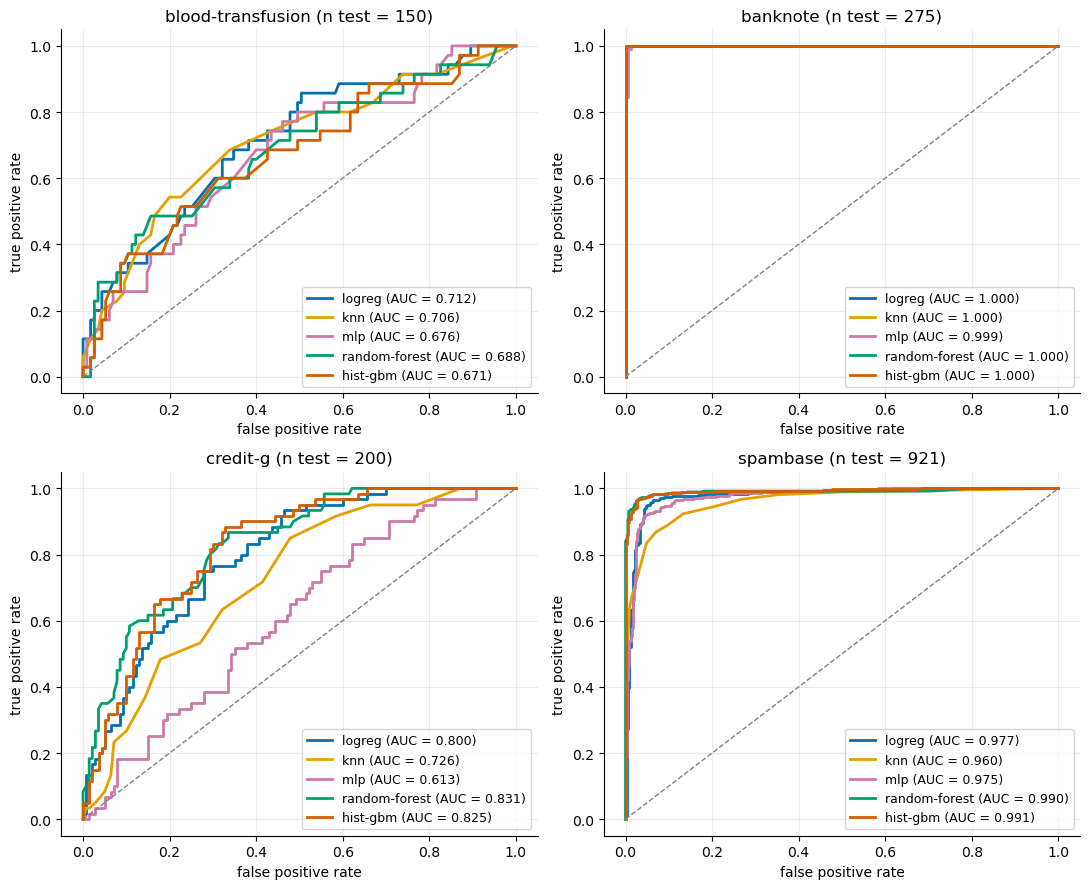

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, (X, y, _)) in zip(axes.ravel(), DATASETS.items()):
    # same 60 / 20 / 20 split as holdout_study
    X_tr, X_rest, y_tr, y_rest = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
    X_cal, X_te, y_cal, y_te = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=SEED)
    for m, (est, grid) in model_zoo().items():
        search = GridSearchCV(clone(est), grid, scoring="roc_auc", cv=3).fit(X_tr, y_tr)
        p = search.predict_proba(X_te)[:, 1]
        fpr, tpr, _ = roc_curve(y_te, p)
        ax.plot(fpr, tpr, color=MODEL_COLORS[m], lw=2, label=f"{m} (AUC = {roc_auc_score(y_te, p):.3f})")
    ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
    ax.set_title(f"{name} (n test = {len(y_te)})"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

### 6.2 Calibration and conformal prediction figures

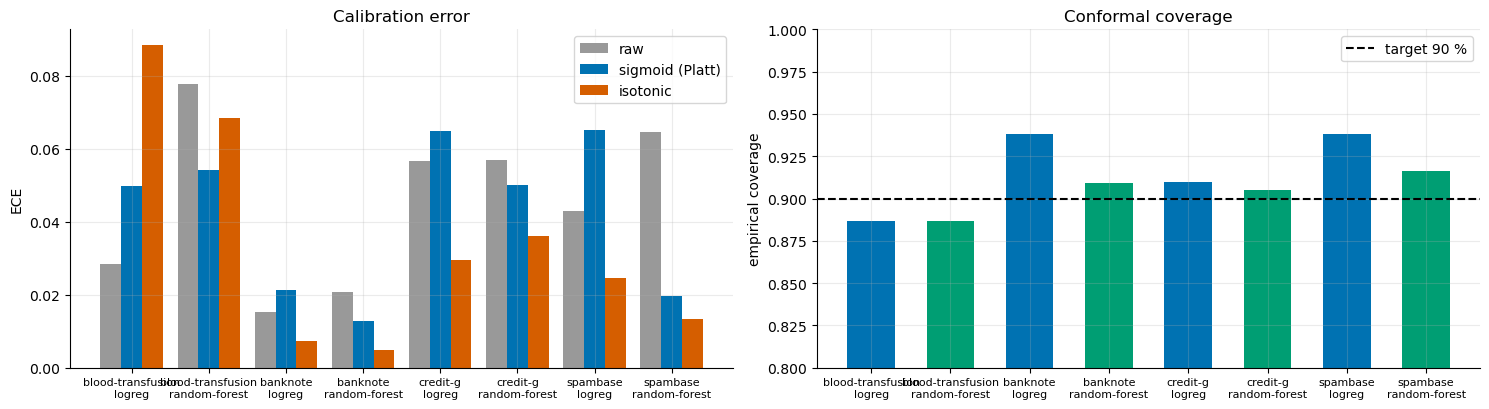

In [29]:
# Left: ECE before / after recalibration (lower = better calibrated). Right: conformal coverage vs the 90 % target.
labels = [f"{r.dataset}\n{r.model}" for r in holdout_df.itertuples()]
xpos = np.arange(len(holdout_df)); w = 0.27
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.2))
for k, (col, lab, colr) in enumerate([("ece_raw", "raw", "#999999"), ("ece_sigmoid", "sigmoid (Platt)", "#0072B2"), ("ece_isotonic", "isotonic", "#D55E00")]):
    a1.bar(xpos + (k - 1) * w, holdout_df[col], w, label=lab, color=colr)
a1.set_xticks(xpos); a1.set_xticklabels(labels, fontsize=8); a1.set_ylabel("ECE"); a1.set_title("Calibration error"); a1.legend()
bars = a2.bar(xpos, holdout_df.conformal_coverage, 0.6, color=[MODEL_COLORS[m] for m in holdout_df.model])
a2.axhline(1 - CONFORMAL_ALPHA, color="black", ls="--", label="target 90 %")
a2.set_ylim(0.8, 1.0); a2.set_xticks(xpos); a2.set_xticklabels(labels, fontsize=8)
a2.set_ylabel("empirical coverage"); a2.set_title("Conformal coverage"); a2.legend()
plt.tight_layout(); plt.show()

## 7. Fit time per outer fold (seconds, mean) and conclusion

The timings are only indicative (they depend on the machine and on other running jobs).

In [30]:
folds_df.pivot_table(index="dataset", columns="model", values="fit_seconds", aggfunc="mean")[MODELS].loc[list(SUITE)].round(2)

model,logreg,knn,mlp,random-forest,hist-gbm
dataset,,,,,
blood-transfusion,0.13,0.07,0.65,4.93,3.62
banknote,0.17,0.06,0.63,5.97,4.11
credit-g,0.10,0.12,0.69,5.87,5.35
spambase,0.32,0.27,3.29,6.94,8.50


### Reading the results

* Compare the **best** column of section 5.4 across datasets: if the winner changes from one dataset to another, no algorithm is universally best.
* Section 5.5 gives the formal answer across datasets: only an average-rank gap larger than the critical difference is significant.
* Section 5.3 shows how many apparent wins vanish once the overlap between CV training sets is accounted for.
* Section 6 shows the uncertainty of a single split (AUC interval), recalibration effects, and whether conformal sets reach their 90 % target.